# Experimental apartment layouts

Inspect bounded residential layout generation, type mix, access and the explicit fallback policy.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW.

## Understanding the API in this lesson

`ZoningSpec(mode="apartments")` requests a bounded procedural residential layout. `ApartmentLayoutSpec` defines circulation and access constraints; its `ApartmentType` entries supply acceptable area ranges and soft target shares. These targets do not reconstruct measured apartment plans.

A full building also needs residential occupancy and dwelling/common partition constructions. Repeated facade openings affect where window-clear cuts are possible. The shared geometry-pipeline figure explains why the layout, openings and thermal parents must remain compatible. Review the achieved plan before using a residential type mix as a stock assumption.

Reference: [How geometry feeds compilation, physical quantities and inspection](../../docs/figures/geometry-pipeline.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Request a residential layout

Apartment zoning needs residential use and physical dwelling/common partition constructions. Target shares are soft layout goals; they are not a reconstruction of observed floorplans.

### Read the code and output

The type table expresses desired ranges, not a guarantee of exact achieved shares. A valid specification can still fail during geometric generation when no complete layout satisfies the bounded search. Inspect the report and the actual floorplate rather than treating input validation as proof that the requested plan exists.

,name,min_area_m2,max_area_m2,target_share
0,small,20.0,65.0,0.5
1,large,65.0,120.0,0.5


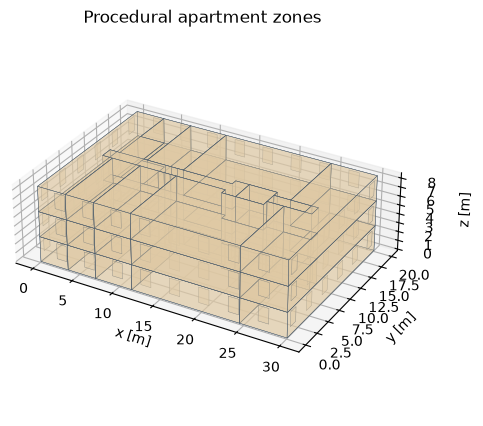

In [2]:
b = building()
types = (ApartmentType(name="small",
                       min_area_m2=20,
                       max_area_m2=65,
                       target_share=.5),
        ApartmentType(name="large",
                      min_area_m2=65,
                      max_area_m2=120,
                      target_share=.5))
controls = ApartmentLayoutSpec(types=types)
b = b.updated(facade=b.facade.updated(layout=WindowLayoutSpec(mode="wwr")),
              use=b.use.updated(occupancy_category="residential"),
              envelope=b.envelope.updated(dwelling_partition=b.envelope.intermediate_floor,
                                          common_partition=b.envelope.intermediate_floor),
              geometry=b.geometry.updated(zoning=ZoningSpec(mode="apartments",
                                                            apartments=controls)))
table([t.model_dump() for t in controls.types])
preview(b, "Procedural apartment zones")

## Check floorplate coverage and access

The resolved report contains the actual layout and any approximation. Floorplate generation must cover the footprint; type targets must not be mistaken for hard area assignments.

### Read the code and output

`infer_floorplate(...)` is a lower-level inspection helper. Its returned parts carry a polygon, role and type. The union assertion checks full coverage of this outline; the individual-area bars expose circulation and dwelling sizes. This isolated helper call is simpler than the complete opening-constrained building resolution used for the preview.

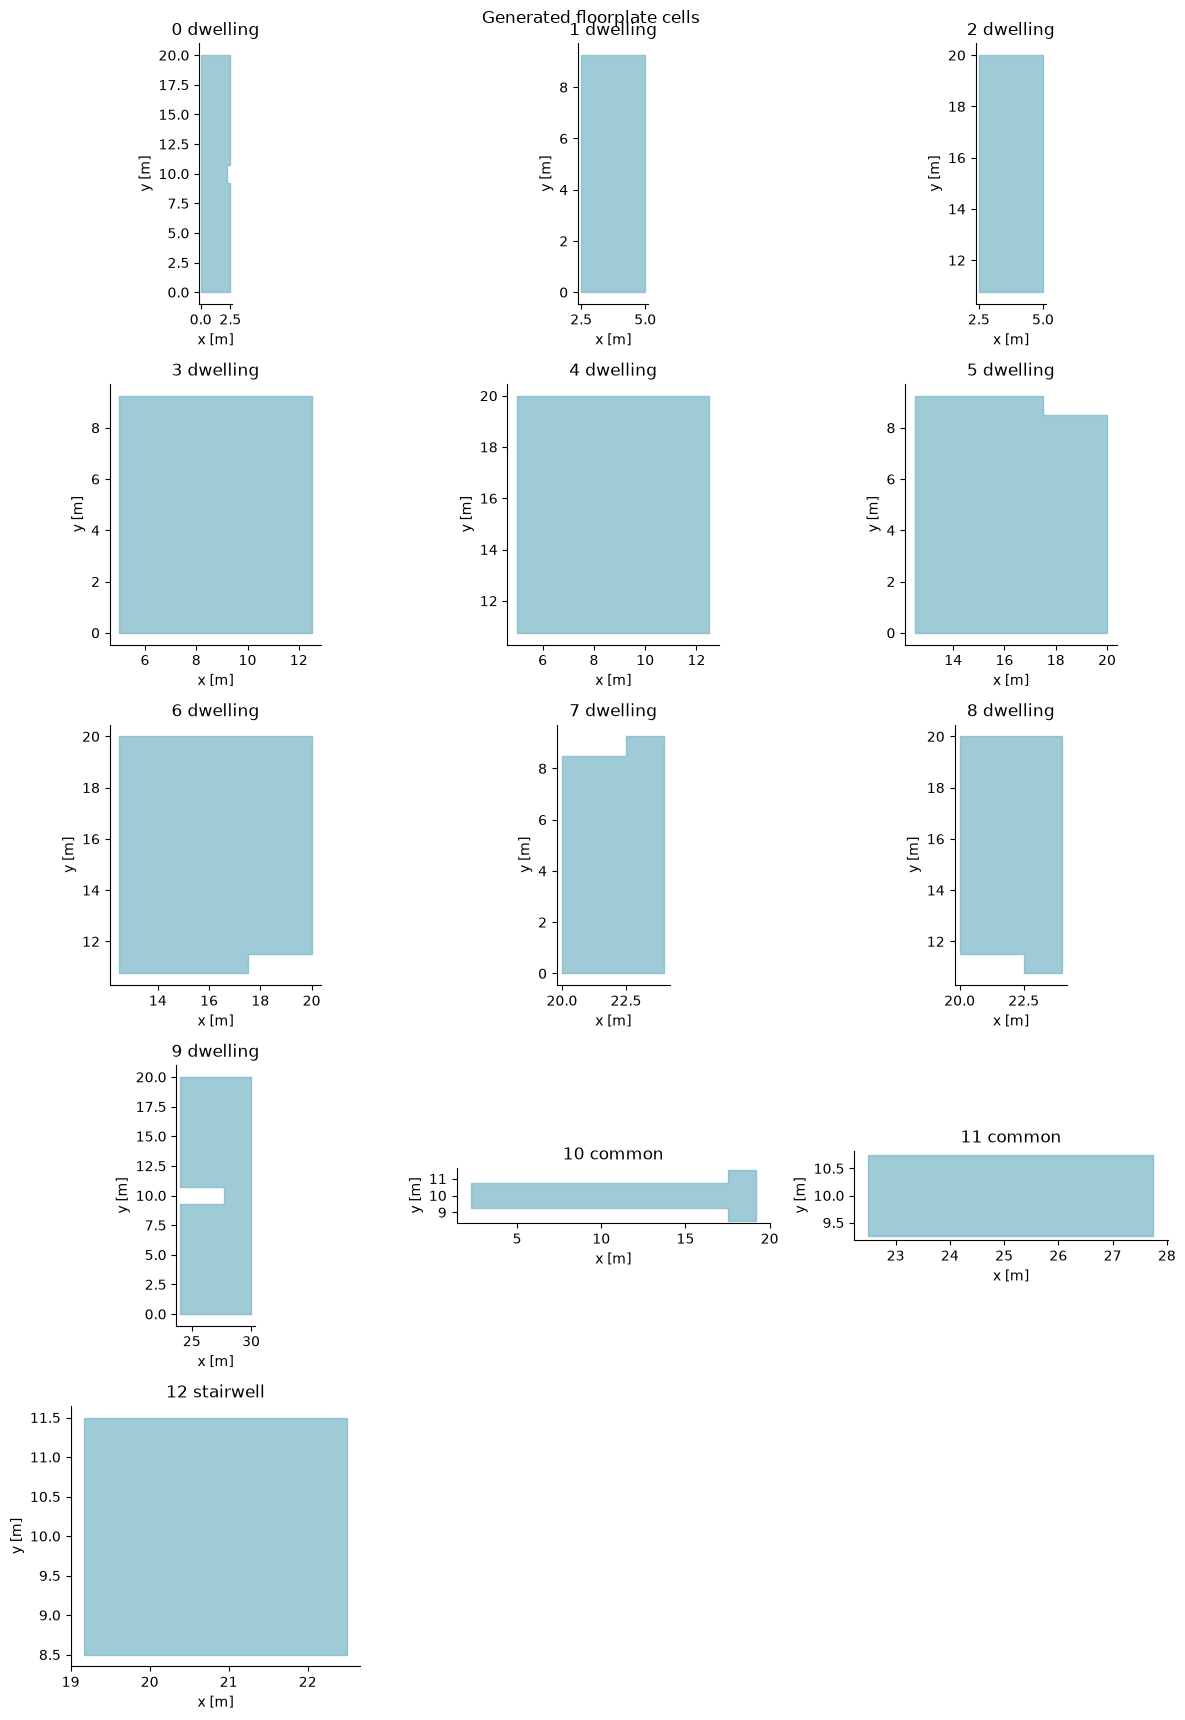

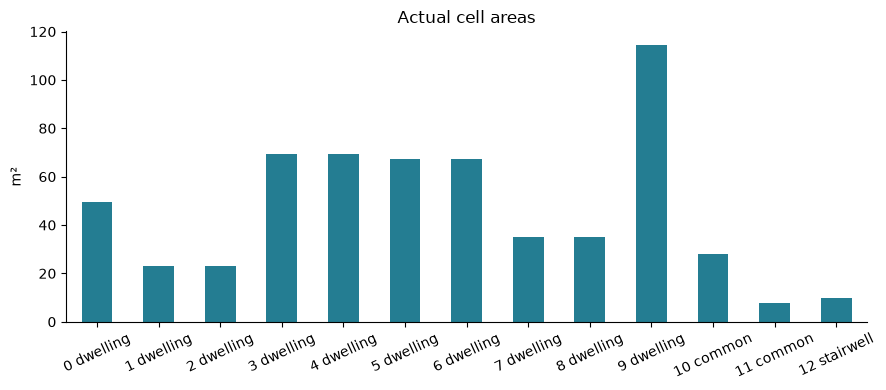

In [3]:
from epsm_core.apartments import infer_floorplate
from shapely import unary_union
outline = b.geometry.parts[0].footprint.polygon
plan, reason = infer_floorplate(outline, controls, [])
assert reason is None
cells = [p for p,kind,typ in plan["parts"]]
assert unary_union(cells).symmetric_difference(outline).area < 1e-6
plans({str(i)+" "+kind:p for i,(p,kind,typ) in enumerate(plan["parts"])}, "Generated floorplate cells")
bars({str(i)+" "+kind:p.area for i,(p,kind,typ) in enumerate(plan["parts"])}, "m²", "Actual cell areas")

## Read requested and effective modes

Use on_failure only when whole-building substitution is acceptable. The report is the source of truth for inclusion in an apartment-detail comparison.

### Read the code and output

The effective-mode assertion confirms this example actually generated apartments. Merely constructing `fallback_policy` at the end does not demonstrate a fallback event; it shows how permission for whole-building substitution is represented. For a real failed case, retain the reason and achieved effective mode before deciding whether to include it.

In [4]:
_, report = geometry_scene(b.geometry, facade=b.facade)
table(report["layout"])
assert report["zoning"]["effective_mode"] == "apartments"
fallback_policy = ZoningSpec(mode="apartments", on_failure="per_storey")
table(fallback_policy.model_dump())

,field,value
0,status,generated
1,parts,"[{'part_id': 'main', 'status': 'generated', 'r..."
2,assumptions,"{'types': [{'name': 'small', 'min_area_m2': 20..."
3,achieved_unit_counts,"{'large': 12, 'small': 12}"


,field,value
0,mode,apartments
1,apartments,"{'types': ({'name': 'studio', 'min_area_m2': 2..."
2,on_failure,per_storey


,field,value
0,mode,apartments
1,apartments,"{'types': ({'name': 'studio', 'min_area_m2': 2..."
2,on_failure,per_storey


## Interpretation and next experiment

Generated layouts are experimental. Track achieved mix, circulation area and substitution rates before using this level of detail across diverse residential buildings.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.